# Лабораторна робота №10
## Трансферне навчання у TensorFlow та Keras 3
**Студент:** Михайло Вахнюк. **Класи:** варіант 5 із ЛР9.

**Мета:** адаптувати ImageNet-модель EfficientNetB0 до трьох класів страв, порівняти навчання голови з частковим fine-tuning, вибрати checkpoint за validation та оцінити лише обрану модель на test.

Обов'язкова частина: feature extraction → fine-tuning block7/top_ без BatchNormalization → вибір за найменшим validation loss → незалежна test-перевірка → аналіз помилок і збереження. Необов'язковий додатковий пошук LR/блоків не виконується.

### 1. Імпорти та середовище

In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','2')
from pathlib import Path
import json, sys, time, hashlib, shutil, platform
from collections import defaultdict
import importlib.metadata as im
import numpy as np
import pandas as pd
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt

### 2. Папки, seed і бюджет двох етапів

Крок 1 методички. Працюємо у .venv проєкту; seed фіксує початкову випадковість, але не гарантує тотожних чисел на іншому обладнанні. Обидва бюджети зафіксовані до test.

In [2]:
ROOT=Path.cwd() if Path('Lab10_Vakhniuk.ipynb').is_file() else Path.cwd()/'Lab10'
LAB9=ROOT.parent/'Lab9'
DATA_DIR=ROOT/'data'
OUT=ROOT/'lab10_results'
OUT.mkdir(parents=True,exist_ok=True)
SEED=42
HEAD_EPOCHS,FINE_EPOCHS=10,10
IMAGE_SIZE=(224,224)
BATCH_SIZE=32
tf.config.threading.set_intra_op_parallelism_threads(6)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
versions={p:im.version(p) for p in ['tensorflow','keras','numpy','pandas','matplotlib','scikit-learn','Pillow','nbformat','nbclient','ipykernel']}
assert int(tf.__version__.split('.')[0])>=2
assert tuple(map(int,tf.__version__.split('.')[:2])) >= (2,16)
assert int(keras.__version__.split('.')[0])>=3
environment={'python':sys.version,'versions':versions,'seed':SEED,'platform':platform.platform(),
             'devices':[str(d) for d in tf.config.list_physical_devices()],
             'threads':6,'batch_size':BATCH_SIZE,'head_epochs':HEAD_EPOCHS,'fine_epochs':FINE_EPOCHS}
(OUT/'environment.json').write_text(json.dumps(environment,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.Series(versions,name='Версія'))
print(environment['devices'])

tensorflow      2.21.0
keras           3.15.1
numpy            2.5.3
pandas           3.0.6
matplotlib      3.11.2
scikit-learn     1.9.1
Pillow          12.3.0
nbformat        5.11.1
nbclient        0.11.0
ipykernel        7.3.0
Name: Версія, dtype: str

["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"]


### 3. Джерело, ліцензійні умови й маніфест ЛР9

Крок 2 методички. Food-101 має фото з Foodspotting; права належать власникам знімків, а не автоматично ETH. У картці ETHZ ліцензія позначена unknown; використання поза науковим fair use потребує погодження з власниками. Не приписуємо набору CC BY чи MIT. Джерела: [Food-101](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/), [ліцензійне застереження](https://huggingface.co/datasets/ethz/food101/blob/main/README.md).

In [3]:
source_manifest=LAB9/'manifest.json'
assert source_manifest.is_file(),'Спочатку підготуйте дані ЛР9 за її README.'
manifest=json.loads(source_manifest.read_text(encoding='utf-8'))
class_names=manifest['class_names']
num_classes=len(class_names)
assert class_names==['beef_tartare','eggs_benedict','miso_soup']
assert manifest['seed']==SEED
assert [len(manifest['splits'][p]) for p in ['train','val','test']]==[1800,450,750]
passport={'dataset':'Food-101','authors':'Bossard, Guillaumin, Van Gool (ECCV 2014)',
 'url':'https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/',
 'licensing_source':'https://huggingface.co/datasets/ethz/food101/blob/main/README.md',
 'license':'Foodspotting image-owner rights; no blanket CC/MIT license claimed; scientific fair use per dataset notice',
 'class_names':class_names,'student_number':5,'food101_indices':[4,34,64],
 'split_source':'Lab9/manifest.json','split_source_sha256':hashlib.sha256(source_manifest.read_bytes()).hexdigest(),
 'split_unchanged':True,'related_object_ids_available':False}
(ROOT/'source_passport.json').write_text(json.dumps(passport,ensure_ascii=False,indent=2),encoding='utf-8')
(ROOT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
print(dict(enumerate(class_names)))

{0: 'beef_tartare', 1: 'eggs_benedict', 2: 'miso_soup'}


### 4. Відтворення каталогів і перевірка всіх зображень

Не змінюємо оригінали. На одному диску створюємо hard link на незмінний файл, за неможливості — копію. Імена та SHA-256 відповідають ЛР9. Це той самий поділ, а не нове випадкове розбиття.

In [4]:
hash_groups=defaultdict(list)
audit=[]
for split,relative_paths in manifest['splits'].items():
    dest=DATA_DIR/split
    expected=set(relative_paths)
    if dest.exists():
        actual={p.relative_to(dest).as_posix() for p in dest.rglob('*') if p.is_file()}
        extra=actual-expected
        assert not extra,f'Зайві файли, не видалено: {sorted(extra)}'
    for rel in relative_paths:
        source=LAB9/'data'/'food101_lab9'/split/rel
        assert source.is_file(),f'Підготуйте ЛР9: {source}'
        target=dest/rel
        digest=hashlib.sha256(source.read_bytes()).hexdigest()
        assert digest==manifest['sha256'][split][rel]
        with Image.open(source) as image:
            image.verify()
        with Image.open(source) as image:
            image.convert('RGB').load()
        target.parent.mkdir(parents=True,exist_ok=True)
        if not target.exists():
            try:
                os.link(source,target)
            except OSError:
                shutil.copy2(source,target)
        assert hashlib.sha256(target.read_bytes()).hexdigest()==digest
        hash_groups[digest].append((split,rel,rel.split('/')[0]))
        audit.append({'split':split,'path':rel,'sha256':digest})

### 5. Відсутність перетинів, дублікатів і конфліктів міток

Класи збалансовані. Метадані не містять груп об’єктів чи зйомок, тому перевірка групових перетинів обмежена; точні хеші не доводять відсутності близьких дублікатів.

In [5]:
overlaps=[]
conflicts=[]
for digest,records in hash_groups.items():
    if len({r[0] for r in records})>1: overlaps.append(records)
    if len({r[2] for r in records})>1: conflicts.append(records)
assert not overlaps and not conflicts
for a,b in [('train','val'),('train','test'),('val','test')]:
    assert set(manifest['splits'][a]).isdisjoint(manifest['splits'][b])
checks={'readable_images':len(audit),'cross_split_hash_duplicates':overlaps,
        'conflicting_labels_by_hash':conflicts,'split_unchanged_from_lab9':True,
        'limitation':'SHA-256 не виявляє змінені копії; ідентифікатори груп об’єктів відсутні'}
(OUT/'data_checks.json').write_text(json.dumps(checks,ensure_ascii=False,indent=2),encoding='utf-8')
pd.DataFrame(audit).to_csv(OUT/'image_audit.csv',index=False)
counts=pd.DataFrame([{'split':s,'class':c,'count':sum(p.startswith(c+'/') for p in paths)}
                    for s,paths in manifest['splits'].items() for c in class_names])
assert all(counts['count']>0)
counts.to_csv(OUT/'split_counts.csv',index=False)
display(counts.pivot(index='class',columns='split',values='count'))
print(checks)

split,test,train,val
class,,,
beef_tartare,250,600,150
eggs_benedict,250,600,150
miso_soup,250,600,150


{'readable_images': 3000, 'cross_split_hash_duplicates': [], 'conflicting_labels_by_hash': [], 'split_unchanged_from_lab9': True, 'limitation': 'SHA-256 не виявляє змінені копії; ідентифікатори груп об’єктів відсутні'}


### 6. Приклади train і функція збереження рисунків

Переглядаємо дев’ять навчальних фото. Гарніри, освітлення, посуд і подача відрізняються; чужі мітки не змінюємо через суб’єктивне враження.

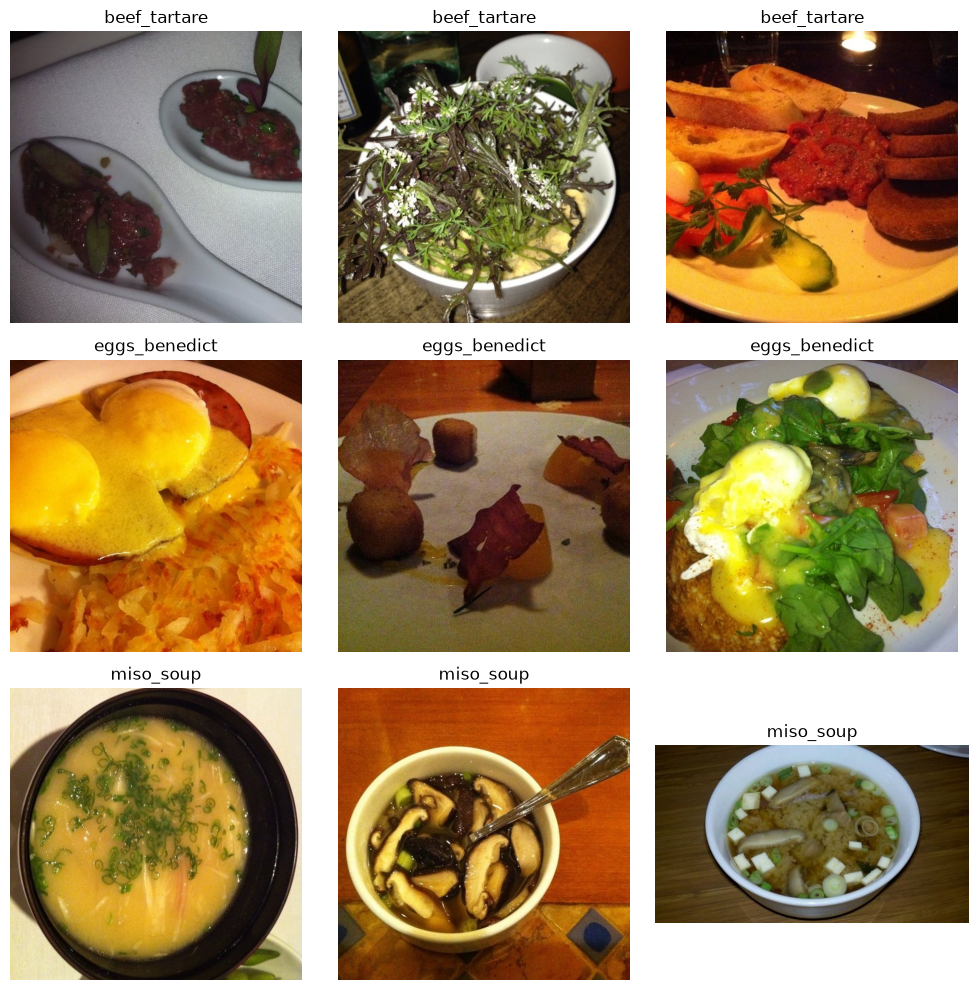

In [6]:
def save_show(fig,name):
    fig.tight_layout()
    fig.savefig(OUT/name,dpi=150,bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig,axes=plt.subplots(3,3,figsize=(10,10))
for row,name in enumerate(class_names):
    paths=[p for p in manifest['splits']['train'] if p.startswith(name+'/')][:3]
    for ax,rel in zip(axes[row],paths):
        with Image.open(DATA_DIR/'train'/rel) as image: ax.imshow(image.convert('RGB'))
        ax.set_title(name); ax.axis('off')
save_show(fig,'train_examples.png')

### 7. Завантаження RGB-батчів 224×224

Крок 3. Validation і test не перемішуємо. Весь набір float32 не кешуємо в RAM; prefetch=1 обмежує буфер. EfficientNetB0 очікує [0,255] й уже має передобробку: додаткового Rescaling немає. [Keras EfficientNet](https://keras.io/api/applications/efficientnet/efficientnet_models/).

In [7]:
def load_split(part,training=False):
    ds=keras.utils.image_dataset_from_directory(DATA_DIR/part,class_names=class_names,
        image_size=IMAGE_SIZE,batch_size=BATCH_SIZE,label_mode='int',color_mode='rgb',
        interpolation='bilinear',shuffle=training,seed=SEED)
    options=tf.data.Options()
    options.threading.private_threadpool_size=4
    options.deterministic=True
    return ds.with_options(options).prefetch(1)

train_ds=load_split('train',True)
val_ds=load_split('val')
images,labels=next(iter(train_ds))
assert images.shape[1:]==(224,224,3) and labels.shape.rank==1
assert float(tf.reduce_min(images))>=0 and float(tf.reduce_max(images))<=255
print('Порядок класів:',class_names)
print(images.shape,images.dtype,labels.shape)
print('Пікселі:',float(tf.reduce_min(images)),float(tf.reduce_max(images)))
print('Один float32 batch, MiB:',images.numpy().nbytes/1024**2)

Found 1800 files belonging to 3 classes.


Found 450 files belonging to 3 classes.


Порядок класів: ['beef_tartare', 'eggs_benedict', 'miso_soup']
(32, 224, 224, 3) <dtype: 'float32'> (32,)
Пікселі: 0.0 255.0
Один float32 batch, MiB: 18.375


### 8. Аугментація, яка зберігає клас страви

Віддзеркалення та невеликий поворот не повинні змінювати вид страви. Аугментація знаходиться в моделі, працює лише під час fit і не створює незалежних test-прикладів.

In [8]:
augmentation=keras.Sequential([
    layers.RandomFlip('horizontal',seed=SEED),
    layers.RandomRotation(.05,seed=SEED+1),
],name='augmentation')
assert np.array_equal(augmentation(images[:2],training=False).numpy(),images[:2].numpy())
print('Аугментація вимкнена в режимі inference.')

Аугментація вимкнена в режимі inference.


### 9. ImageNet-база EfficientNetB0

Крок 4. include_top=False видаляє ImageNet-класифікатор. Перенесені фільтри дають карту 7×7×1280.

In [9]:
base_model=keras.applications.EfficientNetB0(include_top=False,weights='imagenet',input_shape=(224,224,3))
base_model.trainable=False
assert tuple(base_model.output_shape[1:])==(7,7,1280)
print('Вихід бази:',base_model.output_shape)

Вихід бази: (None, 7, 7, 1280)


### 10. Нова голова для трьох класів

GAP перетворює 7×7×1280 на вектор 1280. Dense(3,softmax) працює з int-мітками 0–2; Dropout 0.2 регуляризує голову. training=False для бази збережеться і при fine-tuning, проте не заборонить градієнти для дозволених згорток.

In [10]:
inputs=keras.Input(shape=(224,224,3),name='rgb_image')
x=augmentation(inputs)
x=base_model(x,training=False)
x=layers.GlobalAveragePooling2D(name='gap')(x)
x=layers.Dropout(.2,name='head_dropout')(x)
outputs=layers.Dense(num_classes,activation='softmax',name='dish_class')(x)
model=keras.Model(inputs,outputs,name='food_transfer')

def trainable_count(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_weights))

def compile_model(m,learning_rate):
    m.compile(optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])

compile_model(model,1e-3)
head_params=trainable_count(model)
assert trainable_count(base_model)==0
assert head_params==1280*num_classes+num_classes==3843
model.summary(show_trainable=True)
print('Навчуваних параметрів голови:',head_params)

Model: "food_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ rgb_image (InputLayer)      │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_dropout (Dropout)      │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dish_class (Dense)          │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Навчуваних параметрів голови: 3843


### 11. Контроль ваг і callbacks двох етапів

In [11]:
def weight_digest(weights):
    digest=hashlib.sha256()
    for value in weights: digest.update(np.asarray(value).tobytes())
    return digest.hexdigest()

initial_base_digest=weight_digest(base_model.get_weights())
def callbacks(stage):
    return [keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(OUT/f'{stage}.keras'),monitor='val_loss',save_best_only=True),
        keras.callbacks.CSVLogger(str(OUT/f'{stage}_live_history.csv'))]

plan={'criterion':'minimum validation loss; tie -> feature_extraction',
      'head_lr':1e-3,'fine_lr':1e-5,'head_epochs':HEAD_EPOCHS,'fine_epochs':FINE_EPOCHS,
      'unfreeze_prefixes':['block7','top_'],'batch_normalization_frozen':True,'test_used':False}
(OUT/'experiment_plan.json').write_text(json.dumps(plan,indent=2),encoding='utf-8')

268

### 12. Feature extraction: навчання лише голови

Крок 5. Повна validation передається окремо від test. shuffle=False у fit не скасовує перемішування вже створеного train Dataset.

In [12]:
started=time.perf_counter()
history_head=model.fit(train_ds,validation_data=val_ds,epochs=HEAD_EPOCHS,
    callbacks=callbacks('feature_extraction'),shuffle=False,verbose=2)
head_seconds=time.perf_counter()-started
head_history=pd.DataFrame(history_head.history).rename_axis('epoch_zero_based')
head_history.to_csv(OUT/'feature_extraction_history.csv')
assert initial_base_digest==weight_digest(base_model.get_weights())
print('Заморожена база не змінилася. Час, с:',head_seconds)

Epoch 1/10


57/57 - 105s - 2s/step - accuracy: 0.8228 - loss: 0.4868 - val_accuracy: 0.9578 - val_loss: 0.1650


Epoch 2/10


57/57 - 78s - 1s/step - accuracy: 0.9561 - loss: 0.1615 - val_accuracy: 0.9689 - val_loss: 0.1156


Epoch 3/10


57/57 - 69s - 1s/step - accuracy: 0.9739 - loss: 0.1171 - val_accuracy: 0.9689 - val_loss: 0.1005


... (11 outputs left out)

57/57 - 141s - 2s/step - accuracy: 0.9822 - loss: 0.0582 - val_accuracy: 0.9733 - val_loss: 0.0711


Epoch 10/10


57/57 - 137s - 2s/step - accuracy: 0.9856 - loss: 0.0540 - val_accuracy: 0.9711 - val_loss: 0.0717


Заморожена база не змінилася. Час, с: 1017.0647458000021


### 13. Відновлення найкращих ваг першого етапу

Другий етап починається саме з найкращого checkpoint голови, а не з довільного останнього стану.

In [13]:
head_model=keras.models.load_model(OUT/'feature_extraction.keras')
head_val=head_model.evaluate(val_ds,return_dict=True,verbose=0)
model.set_weights(head_model.get_weights())
del head_model
head_best_epoch=int(np.argmin(history_head.history['val_loss'])+1)
print('Feature extraction:',head_val,'найкраща епоха:',head_best_epoch)

Feature extraction: {'accuracy': 0.9733333587646484, 'loss': 0.071109838783741} найкраща епоха: 9


### 14. Часткове розморожування block7 і top_

Крок 6. Батьківська база trainable=True, але дозволені лише block7/top_. Усі BatchNormalization заморожені. Після зміни trainable створюємо новий Adam і повторно compile. LR зменшується зі 0.001 до 0.00001.

In [14]:
base_model.trainable=True
for layer in base_model.layers:
    layer.trainable=layer.name.startswith(('block7','top_'))
    if isinstance(layer,layers.BatchNormalization): layer.trainable=False
fine_params=trainable_count(model)
assert fine_params>head_params
assert not any(layer.trainable for layer in base_model.layers if isinstance(layer,layers.BatchNormalization))
unfrozen_layers=[layer.name for layer in base_model.layers if layer.trainable_weights]
frozen_before={layer.name:weight_digest(layer.get_weights()) for layer in base_model.layers
               if not layer.trainable and layer.weights}
trainable_before=weight_digest([v.numpy() for v in base_model.trainable_weights])
print('Навчувані шари:',unfrozen_layers)
print('Навчуваних параметрів:',fine_params)
compile_model(model,1e-5)

Навчувані шари:

 ['block7a_expand_conv', 'block7a_dwconv', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'top_conv']
Навчуваних параметрів: 1125427


### 15. Fine-tuning верхніх блоків

training=False зберігає BN-статистики та стохастичні шари бази в режимі inference. Водночас дозволені ваги згорток оновлюються. Аугментація й Dropout голови під час fit залишаються активними.

In [15]:
started=time.perf_counter()
history_fine=model.fit(train_ds,validation_data=val_ds,epochs=FINE_EPOCHS,
    callbacks=callbacks('fine_tuning'),shuffle=False,verbose=2)
fine_seconds=time.perf_counter()-started
fine_history=pd.DataFrame(history_fine.history).rename_axis('epoch_zero_based')
fine_history.to_csv(OUT/'fine_tuning_history.csv')
assert all(frozen_before[layer.name]==weight_digest(layer.get_weights()) for layer in base_model.layers
           if layer.name in frozen_before)
assert trainable_before!=weight_digest([v.numpy() for v in base_model.trainable_weights])
print('Заморожені ваги незмінні, дозволені ваги бази оновилися.')

Epoch 1/10


57/57 - 117s - 2s/step - accuracy: 0.9856 - loss: 0.0575 - val_accuracy: 0.9756 - val_loss: 0.0675


Epoch 2/10


57/57 - 137s - 2s/step - accuracy: 0.9833 - loss: 0.0608 - val_accuracy: 0.9733 - val_loss: 0.0647


Epoch 3/10


57/57 - 139s - 2s/step - accuracy: 0.9822 - loss: 0.0494 - val_accuracy: 0.9756 - val_loss: 0.0638


... (11 outputs left out)

57/57 - 87s - 2s/step - accuracy: 0.9861 - loss: 0.0360 - val_accuracy: 0.9756 - val_loss: 0.0559


Epoch 10/10


57/57 - 87s - 2s/step - accuracy: 0.9883 - loss: 0.0392 - val_accuracy: 0.9756 - val_loss: 0.0549


Заморожені ваги незмінні, дозволені ваги бази оновилися.


### 16. Оцінка найкращого fine-tuning checkpoint

In [16]:
fine_model=keras.models.load_model(OUT/'fine_tuning.keras')
fine_val=fine_model.evaluate(val_ds,return_dict=True,verbose=0)
del fine_model
fine_best_epoch=int(np.argmin(history_fine.history['val_loss'])+1)
print('Fine-tuning:',fine_val,'найкраща епоха:',fine_best_epoch)

Fine-tuning: {'accuracy': 0.9755555391311646, 'loss': 0.05491019785404205} найкраща епоха: 10


### 17. Таблиця validation і вибір до test

Крок 7. Validation accuracy є додатковою характеристикою; визначальний критерій — найменший validation loss. За точної рівності лишаємо feature extraction.

In [17]:
comparison=pd.DataFrame([
 {'stage':'feature_extraction','unfrozen_blocks':'head only','lr':1e-3,'trainable_params':head_params,
  'epochs':len(history_head.history['loss']),'best_epoch':head_best_epoch,'seconds':head_seconds,
  'validation_loss':head_val['loss'],'validation_accuracy':head_val['accuracy']},
 {'stage':'fine_tuning','unfrozen_blocks':'block7, top_; BN frozen','lr':1e-5,'trainable_params':fine_params,
  'epochs':len(history_fine.history['loss']),'best_epoch':fine_best_epoch,'seconds':fine_seconds,
  'validation_loss':fine_val['loss'],'validation_accuracy':fine_val['accuracy']}])
comparison.to_csv(OUT/'stage_comparison.csv',index=False)
selected_stage='fine_tuning' if fine_val['loss']<head_val['loss'] else 'feature_extraction'
decision={'selected_stage':selected_stage,'criterion':plan['criterion'],'test_used':False,
          'comparison':comparison.to_dict('records')}
(OUT/'selection_before_test.json').write_text(json.dumps(decision,indent=2),encoding='utf-8')
best_model=keras.models.load_model(OUT/f'{selected_stage}.keras')
display(comparison)
print('Обрано до test:',selected_stage)

,stage,unfrozen_blocks,lr,trainable_params,epochs,best_epoch,seconds,validation_loss,validation_accuracy
0,feature_extraction,head only,0.00100,3843,10,9,1017.064746,0.07111,0.973333
1,fine_tuning,"block7, top_; BN frozen",0.00001,1125427,10,10,1437.806362,0.05491,0.975556


Обрано до test: fine_tuning


### 18. Криві обох етапів з фактичною межею fine-tuning

Крок 8. Межа визначена фактичною довжиною першої історії, а не запланованими 10 епохами. Пунктиром показаний другий етап.

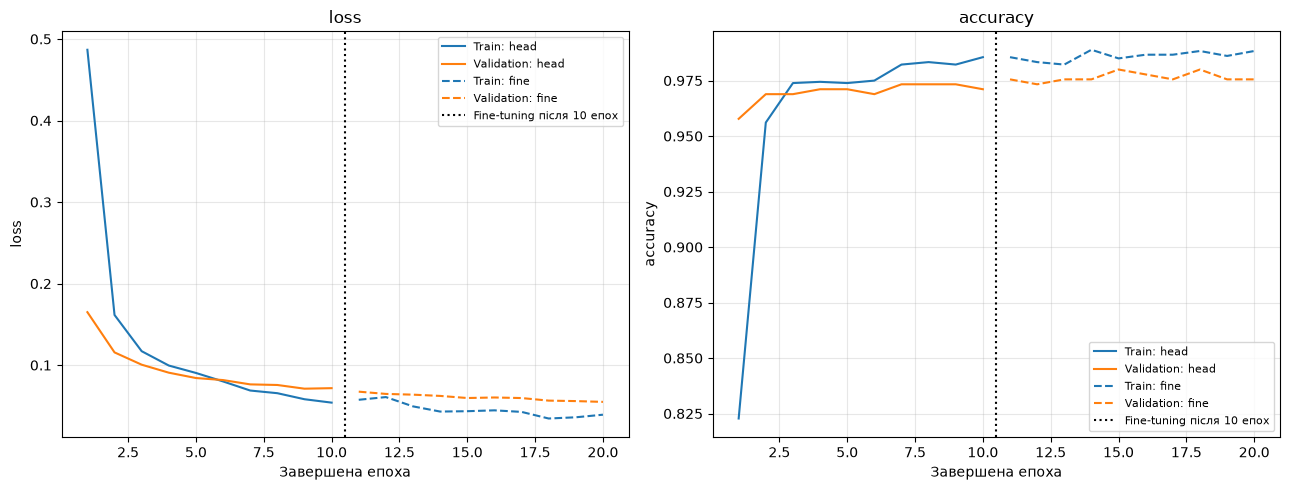

In [18]:
boundary=len(history_head.history['loss'])
head_e=np.arange(1,boundary+1)
fine_e=np.arange(boundary+1,boundary+len(history_fine.history['loss'])+1)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric in zip(axes,['loss','accuracy']):
    ax.plot(head_e,history_head.history[metric],label='Train: head',color='tab:blue')
    ax.plot(head_e,history_head.history['val_'+metric],label='Validation: head',color='tab:orange')
    ax.plot(fine_e,history_fine.history[metric],label='Train: fine',color='tab:blue',ls='--')
    ax.plot(fine_e,history_fine.history['val_'+metric],label='Validation: fine',color='tab:orange',ls='--')
    ax.axvline(boundary+.5,color='black',ls=':',label=f'Fine-tuning після {boundary} епох')
    ax.set(xlabel='Завершена епоха',ylabel=metric,title=metric)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
save_show(fig,'training_curves.png')

### 19. Окремі криві для аналізу кожного етапу

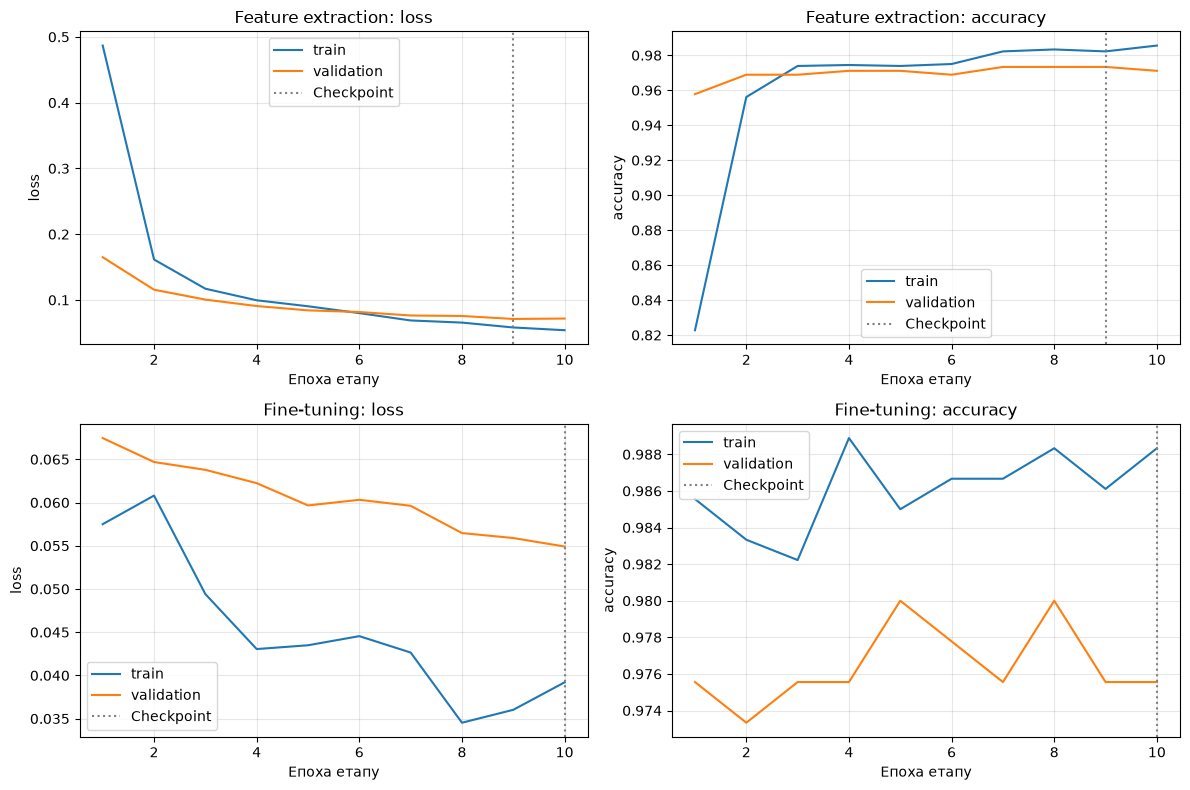

In [19]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for row,(stage,hist) in enumerate([('Feature extraction',history_head),('Fine-tuning',history_fine)]):
    e=np.arange(1,len(hist.history['loss'])+1)
    for col,metric in enumerate(['loss','accuracy']):
        ax=axes[row,col]
        ax.plot(e,hist.history[metric],label='train')
        ax.plot(e,hist.history['val_'+metric],label='validation')
        ax.axvline(int(np.argmin(hist.history['val_loss'])+1),color='gray',ls=':',label='Checkpoint')
        ax.set(title=f'{stage}: {metric}',xlabel='Епоха етапу',ylabel=metric)
        ax.grid(alpha=.3); ax.legend()
save_show(fig,'stage_curves.png')

### 20. Фінальне test-оцінювання лише обраної моделі

Test не використовуємо для зміни LR, блоків або вибору checkpoint. Порівнюємо з ЛР9 лише описово: поділ і класи ті самі, але архітектура, ImageNet-переднавчання та розмір входу відрізняються.

In [20]:
test_ds=load_split('test')
test_metrics=best_model.evaluate(test_ds,return_dict=True,verbose=0)
y_true=np.concatenate([y.numpy() for _,y in test_ds])
probabilities=best_model.predict(test_ds,verbose=0)
y_pred=probabilities.argmax(axis=1)
test_paths=sorted(manifest['splits']['test'])
assert probabilities.shape==(750,num_classes) and np.isfinite(probabilities).all()
np.testing.assert_allclose(probabilities.sum(axis=1),1,atol=1e-5)
np.testing.assert_array_equal(y_true,[class_names.index(p.split('/')[0]) for p in test_paths])
report=classification_report(y_true,y_pred,labels=np.arange(num_classes),target_names=class_names,
                             zero_division=0,output_dict=True)
pd.DataFrame(report).T.to_csv(OUT/'classification_report.csv')
summary={'selected_stage':selected_stage,'test_loss':float(test_metrics['loss']),
 'test_accuracy':float(accuracy_score(y_true,y_pred)),'macro_f1':float(f1_score(y_true,y_pred,average='macro')),
 'test_count':len(y_true),'errors':int(np.sum(y_true!=y_pred))}
(OUT/'test_metrics.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print(classification_report(y_true,y_pred,target_names=class_names,digits=4,zero_division=0))
print(summary)

Found 750 files belonging to 3 classes.


               precision    recall  f1-score   support

 beef_tartare     0.9756    0.9600    0.9677       250
eggs_benedict     0.9644    0.9760    0.9702       250
    miso_soup     0.9920    0.9960    0.9940       250

     accuracy                         0.9773       750
    macro avg     0.9774    0.9773    0.9773       750
 weighted avg     0.9774    0.9773    0.9773       750

{'selected_stage': 'fine_tuning', 'test_loss': 0.05254223197698593, 'test_accuracy': 0.9773333333333334, 'macro_f1': 0.9773109459910424, 'test_count': 750, 'errors': 17}


### 21. Матриця помилок і збереження test-прогнозів

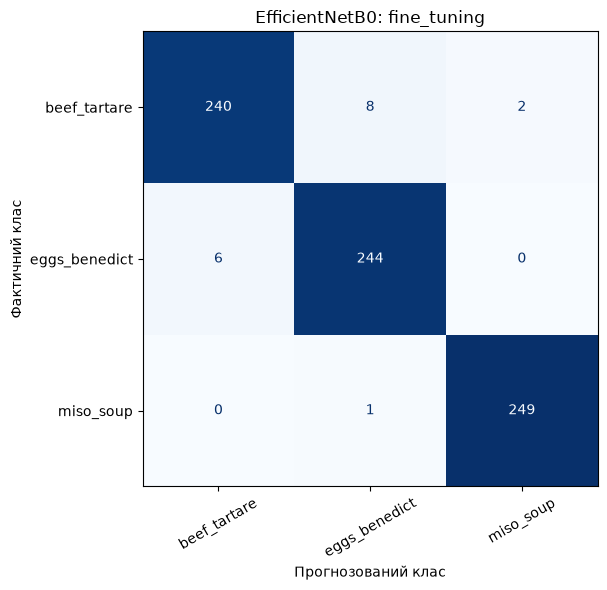

Найчастіша плутанина: beef_tartare → eggs_benedict 8


In [21]:
cm=confusion_matrix(y_true,y_pred,labels=np.arange(num_classes))
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,cmap='Blues',colorbar=False,xticks_rotation=30)
ax.set(title=f'EfficientNetB0: {selected_stage}',xlabel='Прогнозований клас',ylabel='Фактичний клас')
save_show(fig,'confusion_matrix.png')
predictions=pd.DataFrame({'path':test_paths,'true_class':[class_names[i] for i in y_true],
 'predicted_class':[class_names[i] for i in y_pred],'max_softmax':probabilities.max(axis=1)})
for i,name in enumerate(class_names): predictions[f'p_{name}']=probabilities[:,i]
predictions.to_csv(OUT/'test_predictions.csv',index=False)
off=cm.copy(); np.fill_diagonal(off,0)
a,b=np.unravel_index(off.argmax(),off.shape)
print('Найчастіша плутанина:',class_names[a],'→',class_names[b],int(off[a,b]))

### 22. До шести найвпевненіших помилок

Оцінка softmax не гарантує правильності. Розглядаємо форму, фон, посуд, гарнір, освітлення та ракурс; незгода мережі з міткою сама по собі не доводить помилки розмітки.

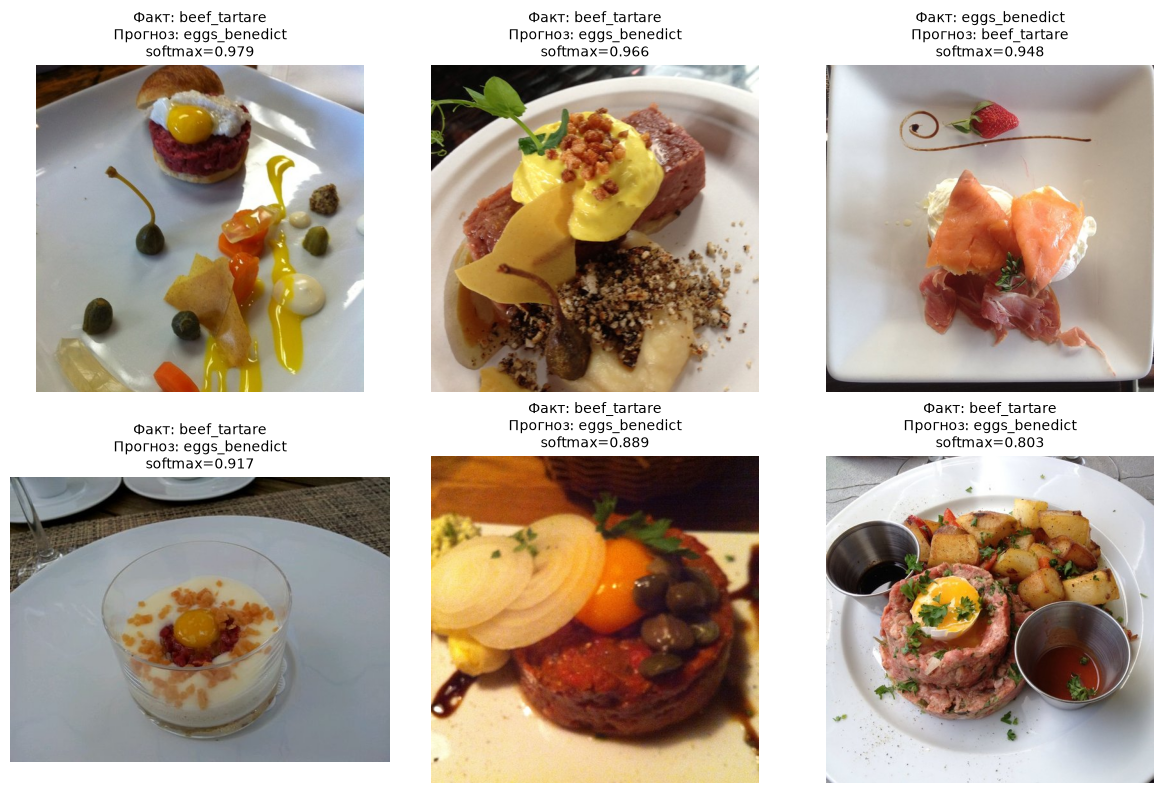

,path,true_class,predicted_class,max_softmax,p_beef_tartare,p_eggs_benedict,p_miso_soup
213,beef_tartare/485390.jpg,beef_tartare,eggs_benedict,0.978698,0.021295,0.978698,0.000007
177,beef_tartare/3568980.jpg,beef_tartare,eggs_benedict,0.966449,0.033488,0.966449,0.000063
414,eggs_benedict/3315572.jpg,eggs_benedict,beef_tartare,0.947541,0.947541,0.045010,0.007449
46,beef_tartare/1616444.jpg,beef_tartare,eggs_benedict,0.917288,0.045657,0.917288,0.037056
175,beef_tartare/3553004.jpg,beef_tartare,eggs_benedict,0.888993,0.110952,0.888993,0.000054
172,beef_tartare/3508685.jpg,beef_tartare,eggs_benedict,0.802894,0.189850,0.802894,0.007256


In [22]:
wrong=np.flatnonzero(y_true!=y_pred)
error_ids=wrong[np.argsort(-probabilities[wrong].max(axis=1),kind='stable')][:6]
predictions.iloc[error_ids].to_csv(OUT/'confident_errors.csv',index=False)
if len(error_ids):
    fig,axes=plt.subplots(2,3,figsize=(12,8))
    for ax,i in zip(axes.flat,error_ids):
        with Image.open(DATA_DIR/'test'/test_paths[i]) as image: ax.imshow(image.convert('RGB'))
        ax.set_title(f'Факт: {class_names[y_true[i]]}\nПрогноз: {class_names[y_pred[i]]}\nsoftmax={probabilities[i].max():.3f}',fontsize=10)
        ax.axis('off')
    for ax in list(axes.flat)[len(error_ids):]: ax.axis('off')
    save_show(fig,'confident_errors.png')
    display(predictions.iloc[error_ids])
else:
    print('Помилок немає.')

### 23. Збереження моделі й повних метаданих

Крок 9. Модель містить передобробку, аугментацію, базу й голову. Для використання потрібні RGB-вхід 224×224 у [0,255] та правильний порядок класів.

In [23]:
best_model.save(OUT/'selected_model.keras')
metadata={'tensorflow':tf.__version__,'keras':keras.__version__,'versions':versions,'seed':SEED,
 'class_names':class_names,'image_size':list(IMAGE_SIZE),'pixel_range':[0,255],'color_mode':'rgb',
 'interpolation':'bilinear','backbone':'EfficientNetB0','weights':'imagenet','include_top':False,
 'external_rescaling':False,'base_training_flag':False,'batch_normalization_frozen':True,
 'selected_stage':selected_stage,'comparison':comparison.to_dict('records'),'test_metrics':summary,
 'unfrozen_layers':unfrozen_layers,'data_source':passport,'split_manifest':'manifest.json',
 'head_base_weights_unchanged':True,'fine_frozen_weights_unchanged':True,'fine_allowed_weights_changed':True}
(OUT/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
(ROOT/'class_names.json').write_text(json.dumps(class_names,indent=2),encoding='utf-8')
(ROOT/'requirements.txt').write_text(''.join(f'{p}=={v}\n' for p,v in versions.items()),encoding='utf-8')
print('Модель та метадані збережені:',OUT)

Модель та метадані збережені: C:\Users\Михайло\Data_Science_Labs\Lab10\lab10_results


### 24. Перевірка повторного завантаження без навчання

In [24]:
probe=next(iter(val_ds))[0][:3].numpy()
before=best_model(probe,training=False).numpy()
np.savez_compressed(OUT/'reload_probe.npz',images=probe,probabilities=before)
restored=keras.models.load_model(OUT/'selected_model.keras')
after=restored(probe,training=False).numpy()
np.testing.assert_allclose(before,after,rtol=1e-5,atol=1e-6)
print('Прогнози після завантаження збігаються.')

Прогнози після завантаження збігаються.


### 25. Порівняння з ЛР9 і висновок за власними числами

**Аналіз графіків.** На першому етапі train loss швидко спадає, validation loss також зменшується й наприкінці майже стабілізується. Найкращий head checkpoint отримано на 9-й епосі, тому останні ваги не обов'язково найкращі. Після межі fine-tuning validation loss продовжує зменшуватися; невеликий розрив із train залишається, але стійкого зростання validation loss не спостерігаємо. Accuracy коливається близько плато: зменшення loss може означати поліпшення оцінок імовірностей навіть без збільшення кількості правильних відповідей. Train виміряно з аугментацією і Dropout, validation — без них, тому ці криві отримано в різних режимах.

**Матриця помилок.** Правильно визначено 240/250 фото тартару, 244/250 яєць Бенедикт і 249/250 місо-супу. Найбільша плутанина — тартар → яйця Бенедикт (8 випадків); у зворотному напрямку — 6. Отже, місо-суп відокремлюється найкраще, а схожа подача двох інших класів залишається складною.

**Приклади хибних прогнозів.** На кількох фото тартару помітні яйце або жовтий соус, хліб і гарнір — ознаки, які візуально зближують його з яйцями Бенедикт. Ракурс зверху, освітлення та посуд можуть приховувати основний інгредієнт. Серед показаних помилок є softmax 0,979: упевненість не гарантує правильності. Окремі мітки можуть потребувати ручної перевірки, але сам хибний прогноз не доводить помилку розмітки; test-мітки та налаштування після цієї перевірки не змінювалися.


In [25]:
lab9_summary=json.loads((LAB9/'results/test_metrics.json').read_text())
improved=fine_val['loss']<head_val['loss']
text=(f'## Висновок\n\n'
 f'Адаптовано EfficientNetB0 з ImageNet до класів {", ".join(class_names)} зі збереженням поділу ЛР9: 1800/450/750. '
 f'Навчання голови з {head_params} навчуваними параметрами дало validation loss={head_val["loss"]:.4f} '
 f'та accuracy={head_val["accuracy"]:.2%} після {len(history_head.history["loss"])} епох. '
 f'Fine-tuning block7/top_ із замороженими BN та LR=1e-5 дав validation loss={fine_val["loss"]:.4f} '
 f'і accuracy={fine_val["accuracy"]:.2%}; отже, донавчання {"допомогло" if improved else "не покращило критерій"} в цьому експерименті. '
 f'За validation обрано {selected_stage}; на test accuracy={summary["test_accuracy"]:.2%}, macro-F1={summary["macro_f1"]:.4f}. '
 f'Для описового порівняння CNN ЛР9 мала accuracy={lab9_summary["test_accuracy"]:.2%}; '
 'різницю не можна приписувати лише одному чиннику, бо використано ImageNet-переднавчання, іншу архітектуру й розмір входу. '
 f'Залишилося {summary["errors"]} хибних прогнозів; їхній аналіз показує межі надійності окремих оцінок softmax. '
 'Ваги заморожених шарів і BN не змінювалися, дозволені згортки оновилися, збереження моделі перевірено збігом прогнозів. '
 'Обмеження: один seed, невелика підмножина, можливий шум міток і відсутність перевірки в інших умовах; '
 'наступною перевірив би лише інший LR fine-tuning зі стартом із того самого head checkpoint і новим незалежним протоколом test.')
display(Markdown(text))
(OUT/'conclusion.md').write_text(text,encoding='utf-8')

## Висновок

Адаптовано EfficientNetB0 з ImageNet до класів beef_tartare, eggs_benedict, miso_soup зі збереженням поділу ЛР9: 1800/450/750. Навчання голови з 3843 навчуваними параметрами дало validation loss=0.0711 та accuracy=97.33% після 10 епох. Fine-tuning block7/top_ із замороженими BN та LR=1e-5 дав validation loss=0.0549 і accuracy=97.56%; отже, донавчання допомогло в цьому експерименті. За validation обрано fine_tuning; на test accuracy=97.73%, macro-F1=0.9773. Для описового порівняння CNN ЛР9 мала accuracy=71.07%; різницю не можна приписувати лише одному чиннику, бо використано ImageNet-переднавчання, іншу архітектуру й розмір входу. Залишилося 17 хибних прогнозів; їхній аналіз показує межі надійності окремих оцінок softmax. Ваги заморожених шарів і BN не змінювалися, дозволені згортки оновилися, збереження моделі перевірено збігом прогнозів. Обмеження: один seed, невелика підмножина, можливий шум міток і відсутність перевірки в інших умовах; наступною перевірив би лише інший LR fine-tuning зі стартом із того самого head checkpoint і новим незалежним протоколом test.

1092

## Контрольні запитання
1. Feature extraction оновлює лише голову; fine-tuning — голову та дозволені block7/top_ згортки.
2. EfficientNetB0 вже має передобробку та очікує [0,255]; повторне ділення порушило б її вхід.
3. Карта зберігає простір 7×7×1280; GAP усереднює простір до вектора 1280.
4. trainable=False виключає ваги з оновлень оптимізатора; training=False задає режим прямого проходу.
5. Після розморожування compile фіксує новий набір навчуваних ваг і новий оптимізатор.
6. Підбір за test пристосовує рішення до тестових даних і робить оцінку оптимістичною.
7. Якщо fine-tuning погіршив validation loss, лишаємо найкращий feature extraction checkpoint.